title: "EGMS vs GNSS in Groningen: does satellite radar see the same subsidence?"
date: "2026-10-17"
summary: "I compare ground motion from the European Ground Motion Service (Sentinel-1 InSAR) with 35 GNSS stations above the Groningen gas field. Part 1 of 2."
tags: [EGMS, InSAR, Sentinel-1, GNSS, Validation]
project: egms-check


**Question:** does EGMS show the same subsidence rate as GNSS stations on the ground? EGMS (European Ground Motion
Service) measures ground motion with the Sentinel-1 radar satellites.

**Data:**
- EGMS L2b Calibrated, release 2020–2024: how each point moves towards or away from the satellite (the line of sight),
  for each satellite track separately;
- GNSS stations from the Nevada Geodetic Laboratory: the position of each antenna every day, above the Groningen gas field.

**Method:** for each station we take the EGMS points within 100 m. We convert the GNSS motion to the direction of the
satellite. Then we compare the speed of motion in mm per year. We set the pass/fail limits before the calculations.


In [1]:
#| include: false
#@title Setup: connect to Google Drive and load the results
from google.colab import drive
drive.mount('/content/drive')
import json, re, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown, HTML
PROJECT_DIR = '/content/drive/MyDrive/GeoWorldLook/egmscheck'
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
for m in [m for m in sys.modules if m.startswith('step_0')]:
    del sys.modules[m]          # always use the code on Drive: an old cached module caused KeyError
from step_05_colab_run import (CHECK_CONFIG, region_paths, levelling_check_paths, _levelling_check_examples,
                               _example_sites, _read_sites, _sources)
rt = {'PROJECT_DIR': PROJECT_DIR}
CODE = subprocess.run(['git', '-C', PROJECT_DIR, 'log', '-1', '--format=%h on %ci'], capture_output=True, text=True).stdout.strip()
print('Results calculated with code:', CODE)
NEXT_STEP = ('In EGMS_Monitoring.ipynb, run the start cells (they copy the current code to Drive) and the calculation '
             'cells for this case. Then run this notebook again.')

def require(paths, keys, columns=None):
    # Results older than the notebook: say clearly what to run (instead of KeyError or an empty cell).
    old = [k for k in keys if k not in paths]
    if old:
        raise RuntimeError(f'The code on Drive ({CODE}) is older than this notebook (missing: {old}). {NEXT_STEP}')
    missing = [Path(paths[k]).name for k in keys if not Path(paths[k]).exists()]
    if missing:
        raise FileNotFoundError(f'Results missing on Drive: {missing}. {NEXT_STEP}')
    for k, cols in (columns or {}).items():
        present = pd.read_csv(paths[k], nrows=0).columns
        if [c for c in cols if c not in present]:
            raise RuntimeError(f'{Path(paths[k]).name} was calculated with older code (missing columns '
                               f'{[c for c in cols if c not in present]}). {NEXT_STEP}')

def show(path, width=850):
    # A missing file is an error (results come from EGMS_Monitoring.ipynb), not an empty cell.
    if not Path(path).exists():
        raise FileNotFoundError(f'Missing {path}: run notebooks/EGMS_Monitoring.ipynb first')
    display(Image(str(path), width=width))

def table(df):
    display(HTML(df.to_html(index=False)))

# Results calculated before 2026-10-18 have Polish labels; translate them for display.
_PL_EN = [
    (r'^NIE POTWIERDZONE: .*', 'NOT CONFIRMED: the EGMS subsidence rate is different from GNSS by more than the limits; '
                               'first check the sign, the reference frame and the time window.'),
    (r'^POTWIERDZONE: .*', 'CONFIRMED: EGMS shows the same subsidence rate as GNSS, within the limits.'),
    (r'^CZĘŚCIOWO: .*', 'PARTIAL: the subsidence rate agrees, but the time series or the check at stable stations is outside the limit.'),
    (r'^NIEROZSTRZYGNIĘTE: .*', 'INCONCLUSIVE: K1 cannot be calculated, so there is no conclusion about the subsidence rate.'),
    (r'(\d+%) par z ', r'\1 of pairs with '), (r'mediana std różnicy', 'median std of the difference'),
    (r'(\d+%) reperów', r'\1 of benchmarks'), (r'brak reperów z', 'no benchmarks with'),
    (r'za mało reperów lub brak zróżnicowania', 'too few benchmarks or no spread in'),
    (r'błąd standardowy', 'standard error'), (r'wyraz wolny', 'intercept'), (r'bliskie 1', 'close to 1'),
    (r'mediana', 'median'), (r'Δh_niw', 'Δh_lev'), (r'v_niw', 'v_lev'), (r'mm/rok', 'mm/yr'),
]

def en(text):
    text = str(text)
    for pattern, replacement in _PL_EN:
        text = re.sub(pattern, replacement, text)
    return text

def passed(x):
    s = str(x)
    return '✔ yes' if s == 'True' else '✘ no' if s == 'False' else '— not calculated'

def criteria(path, codes):
    t = pd.read_csv(path)
    t = t[t['kryterium'].str[:2].isin(codes)]
    return pd.DataFrame({'code': t['kryterium'].str[:2].to_numpy(), 'Criterion': t['kryterium'].map(en).to_numpy(),
                         'Result': t['wynik'].map(en).to_numpy(), 'Limit': t['próg'].map(en).to_numpy(),
                         'Passed': t['spełnione'].map(passed).to_numpy()})
G = region_paths(rt, CHECK_CONFIG, 'groningen')
require(G, ['sites', 'gnss_compare', 'verdict_l2b'])

Mounted at /content/drive
Results calculated with code: 2a326ec on 2026-10-15 12:48:10 +0000


## 1. How much data we have

In [2]:
#@title Number of stations and station–track pairs
sites = _read_sites(G)
gn = sites[sites['site_type'] == 'gnss']
gc = pd.read_csv(G['gnss_compare'], dtype={'site': str, 'track': str})
pairs = gc[(gc['product'] == _sources(CHECK_CONFIG)['L2B']) & (gc['status'] == 'ok')
           & (gc['radius_m'] == CHECK_CONFIG['method']['radius_main_m'])]
display(Markdown(f"- **{len(gn)} GNSS stations**: {int((gn['group'] == 'osiadająca').sum())} subsiding "
                 f"and {int((gn['group'] == 'stabilna').sum())} stable\n"
                 f"- **{len(pairs)} station–track pairs** with complete data (radius {CHECK_CONFIG['method']['radius_main_m']} m)"))

- **35 GNSS stations**: 27 subsiding and 8 stable
- **125 station–track pairs** with complete data (radius 100 m)

## 2. Is the subsidence rate the same?

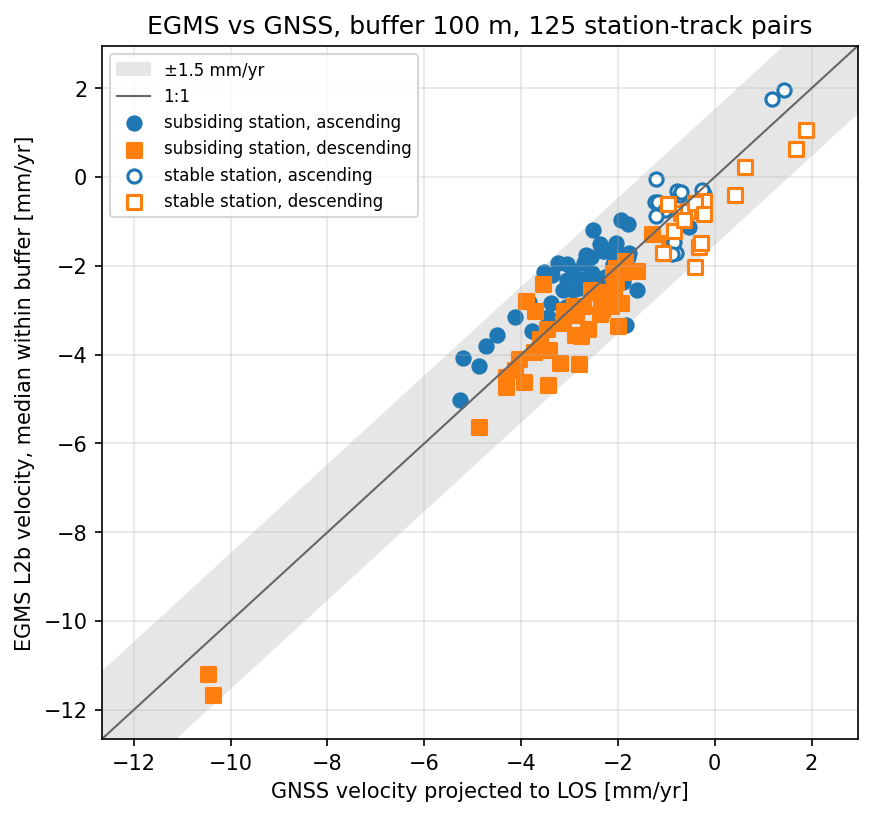

In [3]:
#@title Figure: speed of motion from EGMS and from GNSS
show(G['figures'] / 'groningen_velocity_scatter.png', 620)

**How to read the figure:** each point is one station seen from one satellite track. The horizontal axis shows
GNSS and the vertical axis shows EGMS, both in mm per year. The diagonal line means perfect agreement. The grey band
(±1.5 mm/yr) is the allowed difference. Filled points are subsiding stations, empty points are stable stations.

Almost all points are inside the grey band. Points from ascending tracks (blue) are a little above the line, and points
from descending tracks (orange) are a little below it. This is a small difference in east–west motion between GNSS and
EGMS. It is within the limit, and we did not study it further.

## 3. Results for the criteria set before the calculations

In [4]:
#@title Table of criteria K1–K3
t = criteria(G['verdict_l2b'], ['K1', 'K2', 'K3'])
questions = {'K1': 'Is the subsidence rate the same?', 'K2': 'Are the time series the same?',
             'K3': 'Does EGMS show no false motion at stable stations?'}
t['Criterion'] = t['code'] + ': ' + t['code'].map(questions)
table(t[['Criterion', 'Result', 'Limit', 'Passed']])
display(Markdown('**Result by the rule set in advance:** ' + en(G['verdict_l2b'].with_suffix('.txt').read_text().strip())))

Criterion,Result,Limit,Passed
K1: Is the subsidence rate the same?,99% of pairs with |dv| <= 1.5 mm/yr,>= 80%,✔ yes
K2: Are the time series the same?,median std of the difference 4.7 mm,<= 5.0 mm,✔ yes
K3: Does EGMS show no false motion at stable stations?,max |dv| 1.62 mm/yr,<= 1.5 mm/yr,✘ no


**Result by the rule set in advance:** PARTIAL: the subsidence rate agrees, but the time series or the check at stable stations is outside the limit.

**How to read the table:** K1 and K2 pass, so the subsidence rate and the changes over time agree. K3 fails, but
only just, at one stable station. So the formal result is partial agreement.

## 4. One station over time

Station **AME1**

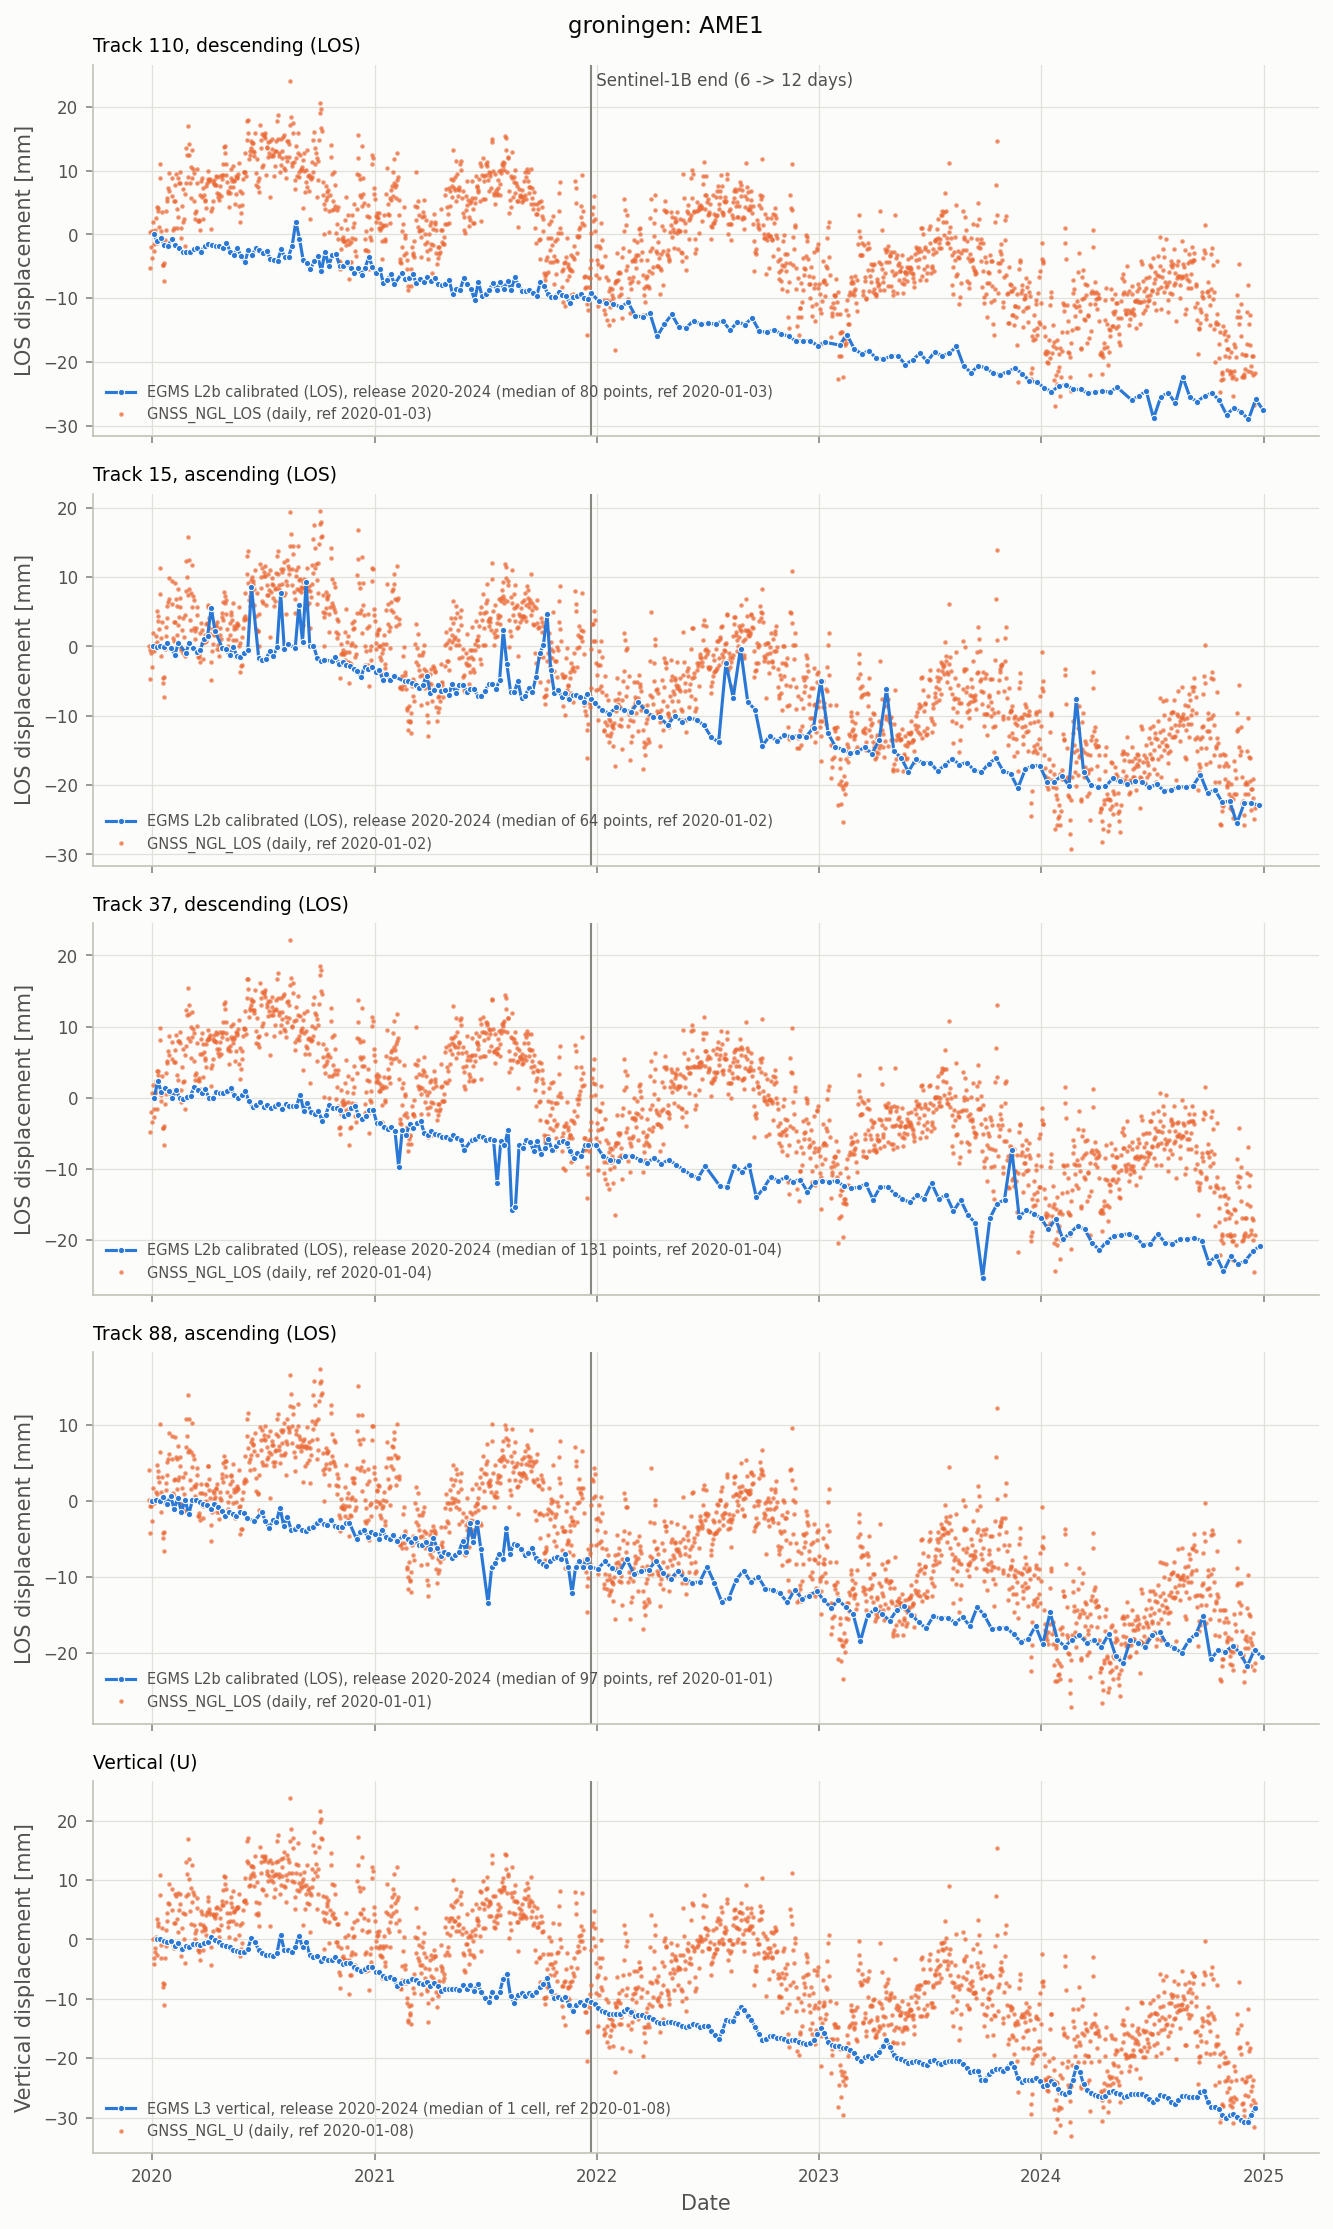

In [5]:
#@title The station that subsides fastest according to GNSS (chosen by a rule, not by hand)
station = _example_sites(sites, None, CHECK_CONFIG['monitoring']['example_rule'])[0]
display(Markdown(f'Station **{station}**'))
show(G['figures'] / f'groningen_series_{station}.png', 900)

**How to read the figure:** each panel is one satellite track (motion towards the satellite, LOS) or the vertical
motion (U). The line is EGMS. The dots are daily GNSS positions converted to the same direction. Both go down at the
same speed.

## Conclusion

- EGMS shows the subsidence above the Groningen gas field well. The GNSS stations on the ground show the same.
- The formal result is **partial agreement**, because the check at stable stations (K3) failed, but only just.
- **Limitation:** EGMS is calibrated with a model based on GNSS stations, so this comparison is not fully independent.
  This is why the second post compares EGMS with levelling, which does not use GNSS.

**Sources:** EGMS (Copernicus Land Monitoring Service); GNSS: Nevada Geodetic Laboratory (Blewitt et al. 2016, 2018);
method and limits: Koudogbo et al. (2025) EGMS Validation Report, Fabris & Nazari (2026).

---

The full notebook and all the code are on GitHub: [Showcase_1_GNSS_Groningen.ipynb](https://github.com/geoworldlook/egms-check/blob/main/notebooks/Showcase_1_GNSS_Groningen.ipynb) in the [egms-check](https://github.com/geoworldlook/egms-check) repository.